# Catatan untuk pembaca

Notebook ini adalah **pipeline asli skripsi** dan output-nya dibiarkan apa adanya. Beberapa hal perlu diperhatikan kalau mau menjalankannya ulang:

- Dijalankan di Google Colab, jadi path-nya masih `/content/`. Upload file dari folder `data/` ke Colab dulu.
- Kolom `text` (tweet mentah berisi username) sudah dihapus dari CSV di repo. Pelatihan memakai `normalize_text`, jadi tidak terpengaruh. Sel WordCloud terakhir butuh kolom `text` dari dataset Kaggle, dan output-nya dihapus karena memuat username.
- `data_twitter_labeled.csv` dan `data_low_confidence.csv` adalah file perantara yang tidak disimpan di repo. Sel labeling akan membuatnya lagi.
- Output evaluasi di notebook ini berasal dari run 10 epoch, batch size 32, dengan accuracy 0,93. Angka di README mengikuti naskah skripsi (5 epoch, batch size 16, accuracy 0,94).
- Skrip pembangkit `data_augmentasi.csv` tidak termasuk di notebook ini.
- Split dilakukan setelah augmentasi dan undersampling, jadi skor 0,94 perlu dibaca bersama bagian **Keterbatasan** di README. Versi evaluasi yang lebih ketat ada di `evaluasi_tanpa_kebocoran.ipynb`.


# **LABELLING DATA**

In [ ]:
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from tqdm import tqdm

# ==================================================
# 1. Load Dataset
# ==================================================
df = pd.read_csv("/content/data_labeled.csv")   # ganti sesuai file Anda

# ==================================================
# 2. Load HuggingFace Model Aardiiiiy
# ==================================================
model_name = "Aardiiiiy/indobertweet-base-Indonesian-sentiment-analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

sentiment_pipeline = pipeline(
    "text-classification",
    model=model,
    tokenizer=tokenizer,
    max_length=128,
    truncation=True,
    return_all_sco

config.json:   0%|          | 0.00/994 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/235k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
# =====================================# 3. Batching Prediction
# ==================================================
batch_size = 32
labels = []
confidences = []

print("🔄 Auto labeling (batch mode)...")

for i in tqdm(range(0, len(df), batch_size)):
    batch = df["normalize_text"][i:i+batch_size].tolist()

    try:
        results = sentiment_pipeline(batch)   # hasil list of dict
        batch_labels = [r["label"] for r in results]
        batch_scores = [r["score"] for r in results]

        labels.extend(batch_labels)
        confidences.extend(batch_scores)

    except Exception as e:
        batch_len = len(batch)
        labels.extend(["ERROR"] * batch_len)
        confidences.extend([0.0] * batch_len)

df["label"] = labels
df["confidence_score"] = confidences

# ==================================================
# 4. Save Output
# ==================================================
df.to_csv("data_twitter_labeled.csv", index=False)

print("✅ Batching selesai! File disimpan sebagai data_twitter_labeled.csv")

🔄 Auto labeling (batch mode)...


100%|██████████| 589/589 [03:36<00:00,  2.72it/s]


✅ Batching selesai! File disimpan sebagai data_twitter_labeled.csv


## MEMBACA DATA LABELED

In [6]:
import pandas as pd

# Load dataset hasil labeling
df = pd.read_csv("data_twitter_labeled.csv")

# Pisahkan low dan high confidence
df_low_conf = df[df["confidence_score"] < 0.85]
df_high_conf = df[df["confidence_score"] >= 0.85]

# Hitung masing-masing
print("Jumlah data LOW confidence (< 0.85):", len(df_low_conf))
print("Jumlah data HIGH confidence (>= 0.85):", len(df_high_conf))

# Contoh data low confidence
print("\nContoh data LOW confidence:\n")
print(df_low_conf[["normalize_text", "label", "confidence_score"]].head(10))

# Contoh data high confidence
print("\nContoh data HIGH confidence:\n")
print(df_high_conf[["normalize_text", "label", "confidence_score"]].head(10))

# Simpan file
df_low_conf.to_csv("data_low_confidence.csv", index=False)
df_high_conf.to_csv("data_high_confidence.csv", index=False)

print("\n📁 File dipisah menjadi:")
print(" ➤ data_low_confidence.csv")
print(" ➤ data_high_confidence.csv")


Jumlah data LOW confidence (< 0.85): 5044
Jumlah data HIGH confidence (>= 0.85): 13793

Contoh data LOW confidence:

                                       normalize_text     label  \
8                                 betul setuju banget   Neutral   
10                gerakan indonesia damai dan beradab  Positive   
11                            bebaskan nikita mirzani   Neutral   
14               ingat 1 nyawa itu tidak akan kembali  Negative   
17                                        1 kata --->   Neutral   
18                          teletubbies berpelukan???   Neutral   
22                                      bukan lebaran  Negative   
40  enggak malu pak sama polisi di film indosiar ?...  Positive   
44                                      begini doang?   Neutral   
48                                               ter?   Neutral   

    confidence_score  
8           0.675390  
10          0.821864  
11          0.621388  
14          0.654769  
17          0.748726  
18     

## **Load Data with High Confindence Score**

Jumlah data HIGH confidence (>= 0.85):
label
Negative    9978
Neutral     2723
Positive    1092
Name: count, dtype: int64


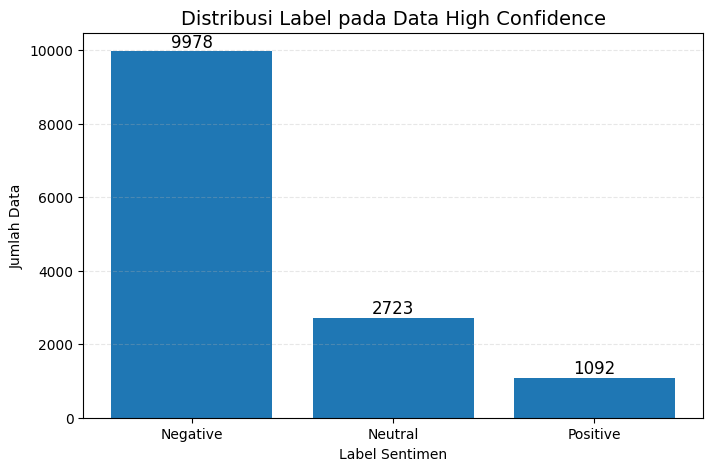

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================
# 1. Load High Confidence Data
# ==============================
df_high = pd.read_csv("/content/data_high_confidence.csv")

# ==============================
# 2. Hitung jumlah data per label
# ==============================
label_counts = df_high["label"].value_counts()

print("Jumlah data HIGH confidence (>= 0.85):")
print(label_counts)

# ==============================
# 3. Plot Bar Chart
# ==============================
plt.figure(figsize=(8, 5))

bars = plt.bar(label_counts.index, label_counts.values)

# Tambahkan angka di atas batang
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 1,
             str(height),
             ha='center', va='bottom', fontsize=12)

plt.title("Distribusi Label pada Data High Confidence", fontsize=14)
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Data")
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()


## **Add Data Augmentation**

✔ Data berhasil digabung dan disimpan sebagai data_combined.csv


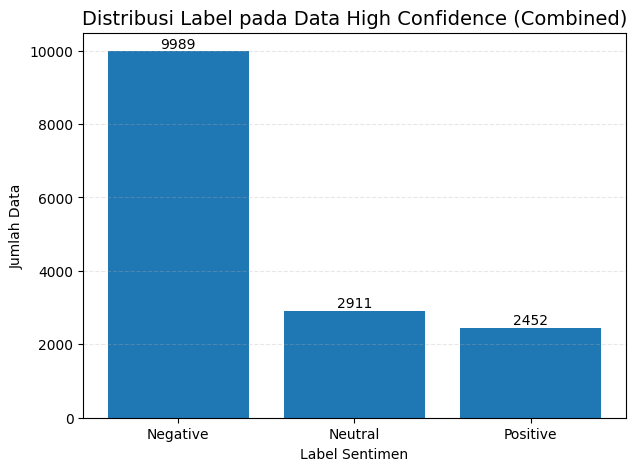

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# =================================
# 1. Load kedua dataset high confidence
# =================================
df_high = pd.read_csv("/content/data_high_confidence.csv")
df_aug = pd.read_csv("/content/data_augmentasi.csv")

# =================================
# 2. Gabungkan dataset
# =================================
df_combined = pd.concat([df_high, df_aug], ignore_index=True)

# Opsional: hapus duplikat jika ada
df_combined = df_combined.drop_duplicates()

# Simpan hasil gabungan
df_combined.to_csv("/content/data_combined.csv", index=False)

print("✔ Data berhasil digabung dan disimpan sebagai data_combined.csv")

# =================================
# 3. Hitung jumlah per label
# =================================
label_counts = df_combined["label"].value_counts()

# =================================
# 4. Plot distribusi label
# =================================
plt.figure(figsize=(7,5))
bars = plt.bar(label_counts.index, label_counts.values)

# Tambahkan angka di atas bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(bar.get_height()),
        ha='center', va='bottom'
    )

plt.title("Distribusi Label pada Data High Confidence (Combined)", fontsize=14)
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Data")
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()


### **Undersampling Data**

In [9]:
import pandas as pd

# ============================================
# 1. Pisahkan data per label
# ============================================
df_neg = df_combined[df_combined["label"] == "Negative"]
df_neu = df_combined[df_combined["label"] == "Neutral"]
df_pos = df_combined[df_combined["label"] == "Positive"]

print("Sebelum undersampling:")
print("Negative :", len(df_neg))
print("Neutral  :", len(df_neu))
print("Positive :", len(df_pos))

# ============================================
# 2. Cari ukuran sampling berdasarkan class terkecil
# ============================================
min_size = min(len(df_neg), len(df_neu), len(df_pos))
print("\nUkuran undersampling otomatis :", min_size)

# ============================================
# 3. Sort berdasarkan confidence_score (descending)
#    lalu ambil min_size teratas
# ============================================
df_neg_top = df_neg.sort_values(by="confidence_score", ascending=False).head(min_size)
df_neu_top = df_neu.sort_values(by="confidence_score", ascending=False).head(min_size)
df_pos_top = df_pos.sort_values(by="confidence_score", ascending=False).head(min_size)

# ============================================
# 4. Combine & Shuffle
# ============================================
df_balanced = pd.concat([df_neg_top, df_neu_top, df_pos_top], ignore_index=True)
df_balanced = df_balanced.sample(frac=1, random_state=42)  # shuffle

# ============================================
# 5. Export
# ============================================
df_balanced.to_csv("data_balanced.csv", index=False)

print("\nSetelah balancing:")
print(df_balanced['label'].value_counts())

print("\n📁 Dataset seimbang disimpan sebagai: data_balanced.csv")


Sebelum undersampling:
Negative : 9989
Neutral  : 2911
Positive : 2452

Ukuran undersampling otomatis : 2452

Setelah balancing:
label
Negative    2452
Neutral     2452
Positive    2452
Name: count, dtype: int64

📁 Dataset seimbang disimpan sebagai: data_balanced.csv


In [10]:
import os
os.environ["WANDB_DISABLED"] = "true"


# TRAINING MODEL 2

## **Install Depedencies**

In [11]:
!pip install datasets evaluate transformers[torch] scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.2 MB/s eta 0:00:00


## **Load Data Balanced**

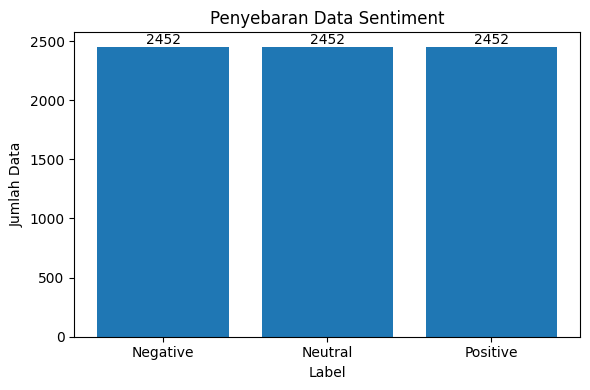

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# === 1. Path file CSV ===
csv_path = "/content/data_balanced.csv"   # ganti dengan nama file Anda

# === 2. Membaca CSV ===
df_balanced = pd.read_csv(csv_path, encoding='utf-8')

# Hitung jumlah tiap label
counts = df_balanced["label"].value_counts()

# Plot bar chart
plt.figure(figsize=(6,4))
bars = plt.bar(counts.index.astype(str), counts.values)  # tidak pakai warna sesuai aturan

# Tambahkan angka di atas tiap bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,   # posisi X (tengah bar)
        height,                            # posisi Y (di atas bar)
        str(height),                       # isi teks
        ha='center', va='bottom'
    )

plt.xlabel("Label")
plt.ylabel("Jumlah Data")
plt.title("Penyebaran Data Sentiment")
plt.tight_layout()
plt.show()


## **Train-Test Split**

In [13]:
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

train_df, test_df = train_test_split(
    df_balanced,
    test_size=0.30,
    stratify=df_balanced["label"],
    random_state=42
)

# Convert to HuggingFace Dataset format
ds_train = Dataset.from_pandas(train_df)
ds_test = Dataset.from_pandas(test_df)

ds = DatasetDict({
    "train": ds_train,
    "test": ds_test
})

ds


DatasetDict({
    train: Dataset({
        features: ['text', 'clean_text', 'normalize_text', 'sentiment', 'label', 'confidence_score', '__index_level_0__'],
        num_rows: 5149
    })
    test: Dataset({
        features: ['text', 'clean_text', 'normalize_text', 'sentiment', 'label', 'confidence_score', '__index_level_0__'],
        num_rows: 2207
    })
})

## **Load Tokenizer & Model IndoBERT**

In [14]:
from transformers import BertTokenizer, AutoModelForSequenceClassification

tokenizer = BertTokenizer.from_pretrained("indobenchmark/indobert-base-p1")

label2id = {"Negative": 0, "Neutral": 1, "Positive": 2}
id2label = {v: k for k, v in label2id.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    "indobenchmark/indobert-base-p1",
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Tokenisasi Dataset

In [15]:
def tokenize(batch):
    return tokenizer(
        batch["normalize_text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

# Tokenizing
tokenized_ds = ds.map(tokenize, batched=True)

# Convert label string → numeric
tokenized_ds = tokenized_ds.map(lambda x: {"labels": label2id[x["label"]]})

# Remove unnecessary columns
cols_to_remove = [col for col in tokenized_ds["train"].column_names
                  if col not in ["input_ids", "attention_mask", "labels"]]

tokenized_ds = tokenized_ds.remove_columns(cols_to_remove)

tokenized_ds.set_format("torch")
tokenized_ds


Map:   0%|          | 0/5149 [00:00<?, ? examples/s]

Map:   0%|          | 0/2207 [00:00<?, ? examples/s]

Map:   0%|          | 0/5149 [00:00<?, ? examples/s]

Map:   0%|          | 0/2207 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 5149
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2207
    })
})

## **Metrics (Accuracy, F1, Precision, Recall, Confusion Matrix)**

In [16]:
import evaluate
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    # Confusion matrix & classification report dihitung setelah training
    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "f1": f1.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "precision": precision_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall": recall_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
    }


## **Training IndoBERT**

In [19]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="results",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    load_best_model_at_end=True,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["test"],
    compute_metrics=compute_metrics,
)
import datasets
datasets.config.TORCHVISION_AVAILABLE = False


trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.067777,0.467336,0.919348,0.919180,0.920700,0.919348
2,0.059329,0.309640,0.931128,0.931122,0.931136,0.931128
3,0.019889,0.413890,0.927050,0.926923,0.927864,0.927050
4,0.007350,0.451296,0.932488,0.932619,0.933124,0.932488
5,0.002339,0.501695,0.934753,0.934727,0.934765,0.934753
6,0.000451,0.522840,0.937019,0.936988,0.937213,0.937019
7,0.000337,0.527130,0.935659,0.935640,0.935650,0.935659
8,0.003148,0.495786,0.939284,0.939413,0.939826,0.939284
9,0.000036,0.500350,0.938831,0.938953,0.939344,0.938831
10,0.000034,0.501020,0.939284,0.939380,0.939654,0.939284


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1610, training_loss=0.016068972393245614, metrics={'train_runtime': 1329.6372, 'train_samples_per_second': 38.725, 'train_steps_per_second': 1.211, 'total_flos': 3386927469703680.0, 'train_loss': 0.016068972393245614, 'epoch': 10.0})

## **Evaluasi Lengkap (Confusion Matrix + Classification Report)**

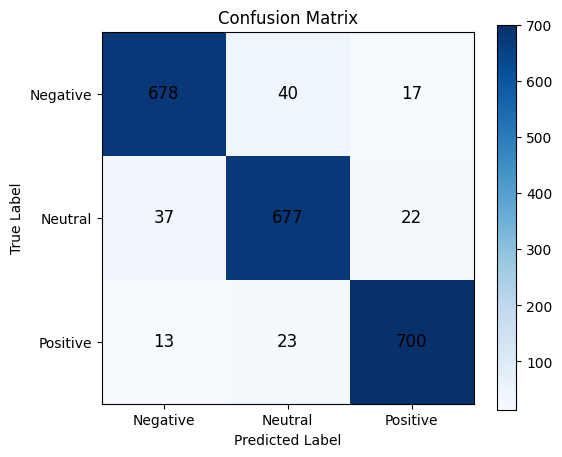


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Negative       0.93      0.92      0.93       735
     Neutral       0.91      0.92      0.92       736
    Positive       0.95      0.95      0.95       736

    accuracy                           0.93      2207
   macro avg       0.93      0.93      0.93      2207
weighted avg       0.93      0.93      0.93      2207



In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Get predictions
predictions = trainer.predict(tokenized_ds["test"])
preds = np.argmax(predictions.predictions, axis=-1)
labels = predictions.label_ids

# Confusion Matrix
cm = confusion_matrix(labels, preds)

plt.figure(figsize=(6, 5))

# Gunakan colormap biru gelap → biru terang
plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Tampilkan angka di setiap sel
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 ha='center', va='center', fontsize=12)

plt.colorbar()  # tetap tampilkan bar warna
plt.xticks(np.arange(3), ["Negative", "Neutral", "Positive"])
plt.yticks(np.arange(3), ["Negative", "Neutral", "Positive"])

plt.show()

# Classification Report
print("\nCLASSIFICATION REPORT:")
print(classification_report(labels, preds, target_names=["Negative", "Neutral", "Positive"]))


## **Save Final Model**

In [21]:
trainer.save_model("finetuned_indobert_sentiment")
tokenizer.save_pretrained("finetuned_indobert_sentiment")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('finetuned_indobert_sentiment/tokenizer_config.json',
 'finetuned_indobert_sentiment/tokenizer.json')

In [22]:
import shutil

folder_path = "/content/finetuned_indobert_sentiment"
zip_path = "/content/finetuned_indobert_sentiment"

# Buat zip
shutil.make_archive(zip_path, 'zip', folder_path)

print("Berhasil! File ZIP dibuat di:", zip_path + ".zip")


Berhasil! File ZIP dibuat di: /content/finetuned_indobert_sentiment.zip


## **WordCloud**

In [23]:
!pip install wordcloud


In [24]:
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt


In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# ===============================
# 1. Gabungkan teks per kelas
# ===============================
text_neg = " ".join(df_balanced[df_balanced["label"] == "Negative"]["text"].astype(str))
text_neu = " ".join(df_balanced[df_balanced["label"] == "Neutral"]["text"].astype(str))
text_pos = " ".join(df_balanced[df_balanced["label"] == "Positive"]["text"].astype(str))

# ===============================
# 2. Generate WordClouds
# ===============================
wc_neg = WordCloud(width=1000, height=600, background_color="white").generate(text_neg)
wc_neu = WordCloud(width=1000, height=600, background_color="white").generate(text_neu)
wc_pos = WordCloud(width=1000, height=600, background_color="white").generate(text_pos)

# ===============================
# 3. Plot dalam satu figure
# ===============================
plt.figure(figsize=(18, 12))

# Negative
plt.subplot(1, 3, 1)
plt.imshow(wc_neg, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud — Negative", fontsize=16)

# Neutral
plt.subplot(1, 3, 2)
plt.imshow(wc_neu, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud — Neutral", fontsize=16)

# Positive
plt.subplot(1, 3, 3)
plt.imshow(wc_pos, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud — Positive", fontsize=16)

plt.tight_layout()
plt.show()
